In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import torch

In [3]:
import sys
sys.path.append('../')

from src.data.vfss_v2 import VFSSWindowImageDataset

In [4]:
# vfss_dataset.video_frame_df
# vfss_dataset.video_frame_df[
#     (vfss_dataset.video_frame_df.video_id == 100) & 
#     (vfss_dataset.video_frame_df.frame_id == 8)
# ]

In [58]:
def plot_window_mask_metadata(
        frames: torch.Tensor,
        mask: torch.Tensor,
        metadata: dict, 
        alpha: float = 0.35, 
        max_cols: int = 5,
        figsize_per_subplot: float = 3.5,
        plot_mask: bool = True
    ):
    """
    Plot a 5-frame grayscale window, a mask, and metadata.

    Args:
        frames: torch.Tensor of shape [5, 1, H, W]
        mask: torch.Tensor of shape [1, H, W]
        metadata: dict containing keys like:
            ['frame_id', 'video_id', 'video_frame', 'window_size', 'stride',
             'window_frame_ids', 'selected_labeler', 'original_dim']
    """
    import matplotlib.pyplot as plt
    import math

    if not isinstance(frames, torch.Tensor):
        raise TypeError("frames must be a torch.Tensor")
    if not isinstance(mask, torch.Tensor):
        raise TypeError("mask must be a torch.Tensor")

    H, W = frames.shape[-2], frames.shape[-1]
    
    window_size = frames.shape[0] if frames.ndim == 4 else 1
    
    print(f"frames shape: {frames.shape}, mask shape: {mask.shape}. {H=}, {W=}, {window_size=}")
    
    if mask.shape[-2:] != (H, W):
        raise ValueError(
            f"mask spatial shape must match frames. "
            f"Got frames spatial shape {(H, W)} and mask shape {tuple(mask.shape[1:])}"
        )

    # Move to CPU and detach
    frames = frames.detach().cpu()
    mask = mask.detach().cpu()

    if window_size == 1:
        frames = frames.unsqueeze(0)
    
    print(f"frames shape: {frames.shape}, mask shape: {mask.shape}")
    frame_imgs = frames[:, 0] # [window_size, C, H, W] -> [window_size, H, W]
    print(f"frame_imgs shape: {frame_imgs.shape}")
    
    mask_img = mask[0]          # [H, W]

    window_frame_ids = metadata.get("window_frame_ids", None)
    video_frame = metadata.get("video_frame", None)

    labeled_idx = metadata.get("frame_id", None)

    ncols = min(window_size, max_cols)
    nrows = math.ceil(window_size / ncols)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(ncols * figsize_per_subplot, nrows * figsize_per_subplot)
    )

    if nrows == 1 and ncols == 1:
        axes = [axes]
    elif nrows == 1 or ncols == 1:
        axes = list(axes)
    else:
        axes = axes.ravel()

    window_frame_ids = metadata.get("window_frame_ids", None)

    for i in range(window_size):
        ax = axes[i]
        ax.imshow(frame_imgs[i], cmap="gray")

        title = f"Frame {window_frame_ids[i]}"
        
        if window_frame_ids[i] == labeled_idx:
            title += f" (main)"
            if plot_mask==True:
                ax.imshow(mask_img, cmap="Reds", alpha=alpha)

        ax.set_title(title)
        ax.axis("off")

    for j in range(window_size, len(axes)):
        axes[j].axis("off")
    
    # Build metadata text
    meta_text = "\n".join([
        f"frame_id: {metadata.get('frame_id')}",
        f"video_id: {metadata.get('video_id')}",
    ])
    fig.text(
        0.01,
        0.01,
        meta_text,
        fontsize=10,
        family="monospace",
        va="bottom"
    )

    plt.tight_layout(rect=[0, 0.12, 1, 1])
    plt.show()

In [6]:
dataset_path = '/data_ssd/caioseda/data/dataset_inca_all_frames/'

In [ ]:
x = torch.randint(0, 2, (3, 512, 250))
print(f"x shape before: {x.shape}")
x = x[:, :, ]
x.shape

x shape before: torch.Size([3, 512, 250])


IndexError: index 512 is out of bounds for dimension 1 with size 512

# frames shape: torch.Size([3, 256, 256]), mask shape: torch.Size([256, 256])
frames shape: torch.Size([3, 256, 256]), mask shape: torch.Size([1, 256, 256]). H=256, W=256, window_size=1
frames shape: torch.Size([1, 3, 256, 256]), mask shape: torch.Size([1, 256, 256])
frame_imgs shape: torch.Size([1, 256, 256])


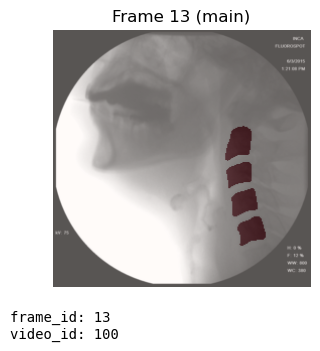

In [59]:
vfss_dataset = VFSSWindowImageDataset(dataset_path=dataset_path, window_size=1, stride=1, repeat_channels=True)
sample = vfss_dataset[2]
frames, mask, metadata = sample['image'], sample['segmentation'], sample['metadata']
print(f"# frames shape: {frames.shape}, mask shape: {mask.shape}")
mask = mask.unsqueeze(0)
plot_window_mask_metadata(frames, mask, metadata)

In [ ]:
torch.manual_seed(42)
image = torch.randint(0, 1, (32, 28, 28), dtype=torch.uint8)
timestep_embedding = torch.randint(0, 5, (32,), dtype=torch.float32)
print(f"image shape: {image.shape}, timestep_embedding shape: {timestep_embedding.shape}")
test = image + timestep_embedding[:, None, None]
test[2, ...]

image shape: torch.Size([32, 28, 28]), timestep_embedding shape: torch.Size([32])


tensor([[3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3.,
         3., 3., 3., 3., 3., 3., 3., 3., 3., 3.],
        [3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3.,
         3., 3., 3., 3., 3., 3., 3., 3., 3., 3.],
        [3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3.,
         3., 3., 3., 3., 3., 3., 3., 3., 3., 3.],
        [3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3.,
         3., 3., 3., 3., 3., 3., 3., 3., 3., 3.],
        [3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3.,
         3., 3., 3., 3., 3., 3., 3., 3., 3., 3.],
        [3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3.,
         3., 3., 3., 3., 3., 3., 3., 3., 3., 3.],
        [3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3.,
         3., 3., 3., 3., 3., 3., 3., 3., 3., 3.],
        [3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3., 3.,
  

In [11]:
metadata

{'frame_id': 10,
 'video_id': 100,
 'video_frame': 'v100_f10',
 'window_size': 5,
 'stride': 1,
 'window_frame_ids': [8, 9, 10, 11, 12],
 'selected_labeler': 'VC',
 'original_dim': (1024, 1024)}

In [13]:
window_size = (16, 16)
num_heads = 4

In [ ]:
# torch.zeros((2 * window_size[0] - 1) * (2 * window_size[1] - 1), num_heads).shape

torch.Size([961, 4])

In [97]:
coords_h = torch.arange(window_size[0])
coords_w = torch.arange(window_size[1])
coords = torch.stack(torch.meshgrid([coords_h, coords_w]))  # 2, Wh, Ww
coords_flatten = torch.flatten(coords, 1)  # 2, Wh*Ww
print(coords_flatten[:, :, None].shape, coords_flatten[:, None, :].shape)
relative_coords = coords_flatten[:, :, None] - coords_flatten[:, None, :]  # 2, Wh*Ww, Wh*Ww
# t1 = coords_flatten[:, :, None]
# t2 = coords_flatten[:, None, :]
# relative_coords[1, :, :]

relative_coords = relative_coords.permute(1, 2, 0).contiguous()  # Wh*Ww, Wh*Ww, 2
relative_coords[:, :, 0] += window_size[0] - 1  # shift to start from 0
relative_coords[:, :, 1] += window_size[1] - 1
relative_coords[:, :, 0] *= 2 * window_size[1] - 1
relative_position_index = relative_coords.sum(-1)  # Wh*Ww, Wh*Ww
relative_position_index
# self.register_buffer("relative_position_index", relative_position_index)

torch.Size([2, 256, 1]) torch.Size([2, 1, 256])


tensor([[480, 479, 478,  ...,   2,   1,   0],
        [481, 480, 479,  ...,   3,   2,   1],
        [482, 481, 480,  ...,   4,   3,   2],
        ...,
        [958, 957, 956,  ..., 480, 479, 478],
        [959, 958, 957,  ..., 481, 480, 479],
        [960, 959, 958,  ..., 482, 481, 480]])

In [124]:
x = torch.randint(0, 10, (3, 2, 3, 2))
x

tensor([[[[1, 2],
          [7, 7],
          [7, 2]],

         [[6, 0],
          [6, 8],
          [4, 6]]],


        [[[4, 6],
          [3, 1],
          [8, 7]],

         [[1, 0],
          [8, 4],
          [3, 1]]],


        [[[4, 4],
          [9, 6],
          [3, 4]],

         [[7, 1],
          [6, 3],
          [7, 2]]]])

In [127]:
y = x.transpose(-2, -1)
print(y.shape)
y


torch.Size([3, 2, 2, 3])


tensor([[[[1, 7, 7],
          [2, 7, 2]],

         [[6, 6, 4],
          [0, 8, 6]]],


        [[[4, 3, 8],
          [6, 1, 7]],

         [[1, 8, 3],
          [0, 4, 1]]],


        [[[4, 9, 3],
          [4, 6, 4]],

         [[7, 6, 7],
          [1, 3, 2]]]])